# RNN assignment · test an idea fairly

Predict the next trading session's Google opening price from a short history of opening prices. This historical teaching example demonstrates sequence preparation and evaluation; it does not establish a profitable trading strategy.

**Outcome:** explain the input shape, keep future information out of fitting, train a compact
recurrent model, and compare it with a simple baseline on identical target dates.

**Suggested time:** 20–30 minutes after the walkthrough.
This is a runnable starter. The working pipeline is supplied; your work is the experiment, evidence and explanation in the learner response cells. The final test is gated until you finish validation.


In [1]:
import os
from pathlib import Path

# This must happen before importing keras. Restart the kernel to change backend.
os.environ.setdefault("KERAS_BACKEND", "torch")
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # Apple GPU lacks one op used by recurrent layers.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True})
print("Configured Keras backend:", os.environ["KERAS_BACKEND"])


Configured Keras backend: torch


## Your core tasks

1. **Trace one example.** Before running the model, write the three dimensions of `X_train`,
   explain `UNITS`, and identify the input dates and target date of the first validation example.
   Explain why the first test input can use December history.
2. **Make a prediction before experimenting.** Compare the supplied 20-day window with **one**
   of 10 or 50 trading days. Write a hypothesis, then change only `LOOKBACK`. Keep the split,
   seed, units, optimizer and stopping rule fixed. Re-run sections 1–6 for each configuration.
3. **Record evidence.** Fill the experiment table with both validation MAE/RMSE, epochs run,
   and the unchanged persistence baseline. Report whether any model beats it.
4. **Choose and freeze.** Choose the neural configuration by validation MAE, state the decision,
   then re-run sections 1–6 with that configuration. Set `RUN_FINAL_TEST = True` once.
   Report final model and persistence scores and one limitation.

**Success criteria:** two controlled runs; correct shapes and target dates; original-unit
metrics; honest baseline comparison; a frozen final configuration; no tuning using test scores.
A lower score than the baseline is not a completion requirement.

**Hint:** increasing the window changes the number of eligible training samples, but our
validation/test target dates stay fixed. Look at `target_pos`, not the number of CSV rows alone.


## 1 · Load the original dated observations and choose a small configuration


In [2]:
# Change one setting at a time during the core experiment.
LOOKBACK = 10  # chosen by validation MAE (20 → 12.520, 10 → 10.327)
UNITS = 16
MAX_EPOCHS = 30
BATCH_SIZE = 32
LEARNING_RATE = 0.001


In [3]:
# Leave as None when using the complete pack. Otherwise point to your CSV folder.
DATA_DIR = None  # Example: Path("/path/to/bootcamp/data")

def data_file(filename, dataset_handle):
    """Prefer the supplied CSV; use the exact public dataset version if needed."""
    roots = ([Path(DATA_DIR).expanduser()] if DATA_DIR is not None else
             [Path("data"), Path("../data"), Path("../../data"), Path(".")])
    for folder in roots:
        candidate = folder / filename
        if candidate.is_file():
            return candidate.resolve()
    try:
        import kagglehub
        folder = Path(kagglehub.dataset_download(dataset_handle))
    except Exception as exc:
        raise RuntimeError(
            f"Cannot locate {filename}. Extract the full pack or set DATA_DIR. "
            "The fallback needs kagglehub, internet access and any access "
            "requirements requested by Kaggle. No replacement data is generated."
        ) from exc
    candidate = folder / filename
    if not candidate.is_file():
        raise FileNotFoundError(f"Expected CSV is missing: {candidate}")
    return candidate


In [4]:
stock_handle = "rahulsah06/gooogle-stock-price/versions/1"

def read_stock(file):
    frame = pd.read_csv(file, usecols=["Date", "Open"])
    frame["Date"] = pd.to_datetime(frame["Date"], format="%m/%d/%Y", errors="raise")
    frame["Open"] = pd.to_numeric(frame["Open"], errors="raise")
    frame = frame.sort_values("Date").set_index("Date")
    if frame.index.has_duplicates or not np.isfinite(frame["Open"]).all():
        raise ValueError("Stock data contains duplicate dates or invalid prices.")
    if not (frame["Open"] > 0).all():
        raise ValueError("Expected positive opening prices.")
    return frame

historical = read_stock(data_file("Google_Stock_Price_Train.csv", stock_handle))
holdout = read_stock(data_file("Google_Stock_Price_Test.csv", stock_handle))
assert historical.index.max() < holdout.index.min(), "Historical and test dates overlap."
series = pd.concat([historical, holdout])
values = series[["Open"]].to_numpy(dtype="float32")
dates = series.index
train_end = int(len(historical) * 0.8)
val_end = len(historical)
assert LOOKBACK < train_end < val_end < len(values)

print("Historical rows:", len(historical), "| Held-out trading days:", len(holdout))
print("Dates:", dates.min().date(), "to", dates.max().date())
historical.head()


c:\Users\donatas.vaiciunas\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 23.4k/23.4k [00:00<00:00, 2.94MB/s]

Extracting files...
Historical rows: 1258 | Held-out trading days: 20
Dates: 2012-01-03 to 2017-01-31


,Open
Date,
2012-01-03,325.25
2012-01-04,331.27
2012-01-05,329.83
2012-01-06,328.34
2012-01-09,322.04


## 2 · Split chronologically, then fit the scaler

Training dates come first, validation dates next, and test dates last. Validation is used for
early stopping and configuration choices. Test labels are used only for the final report.

Fit the scaler using the **training period only**, including the historical context needed
for its first window. Apply that same fitted scaler everywhere. A validation or test value
may transform outside `[0, 1]` when it exceeds the training range; do not refit or clip it to
hide that change. The Dense output is linear, so predictions are not restricted to `[0, 1]`.
See [scikit-learn's leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).


            Period First date  Last date  Rows
  Training history 2012-01-03 2015-12-31  1006
Validation targets 2016-01-04 2016-12-30   252
      Test targets 2017-01-03 2017-01-31    20
Scaler minimum / maximum: [279.12] [776.6]


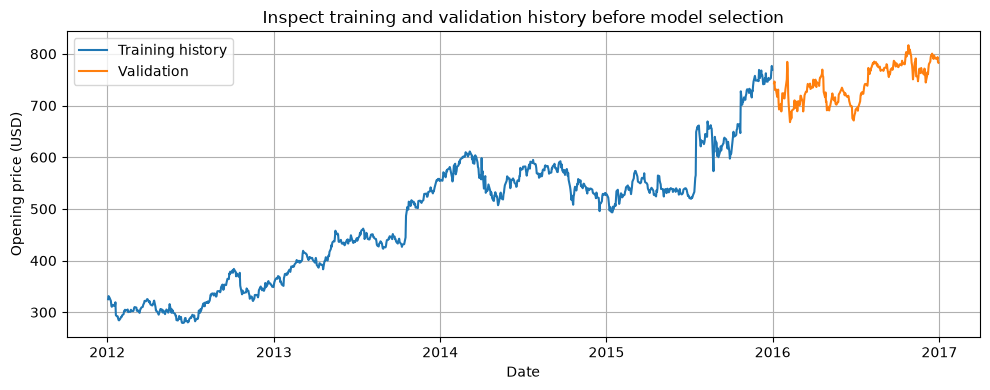

In [5]:
scaler = MinMaxScaler()
scaler.fit(values[:train_end])
scaled_values = scaler.transform(values).astype("float32")
np.testing.assert_allclose(scaler.data_min_, values[:train_end].min(axis=0))
np.testing.assert_allclose(scaler.data_max_, values[:train_end].max(axis=0))

split_summary = pd.DataFrame([
    {"Period": "Training history", "First date": dates[0].date(),
      "Last date": dates[train_end - 1].date(), "Rows": train_end},
    {"Period": "Validation targets", "First date": dates[train_end].date(),
      "Last date": dates[val_end - 1].date(), "Rows": val_end - train_end},
    {"Period": "Test targets", "First date": dates[val_end].date(),
      "Last date": dates[-1].date(), "Rows": len(values) - val_end},
])
print(split_summary.to_string(index=False))
print("Scaler minimum / maximum:", scaler.data_min_, scaler.data_max_)

plt.plot(dates[:train_end], values[:train_end, 0], label="Training history")
plt.plot(dates[train_end:val_end], values[train_end:val_end, 0], label="Validation")
plt.xlabel("Date")
plt.ylabel("Opening price (USD)")
plt.title("Inspect training and validation history before model selection")
plt.legend()
plt.tight_layout()
plt.show()


## 3 · Turn a series into supervised examples

For target position `t`, the input is `values[t - LOOKBACK:t]` and the target is `values[t]`.
The right edge of a Python slice is excluded, so the target is never inside its own input.

Keras recurrent layers receive **(samples, timesteps, features)**. Here there is one measured
feature per step. The number of recurrent units is a separate model setting.
`Input(shape=(LOOKBACK, 1))` omits the batch dimension; it does not mean one timestep with
`LOOKBACK` features. With one timestep, a stateless model sees no earlier step within that sample.

We first create all eligible windows, then assign them by **target date**. Validation/test
windows may include earlier observed values from previous splits. This preserves the first
validation and test targets instead of throwing away a whole window at each boundary.

**Evaluation contract - rolling one-step prediction:** the model and scaler stay fixed. Before
predicting time `t`, all actual observations before `t` are available. Later test predictions
therefore use earlier observed test values. This is appropriate for a forecast updated every
period; it is not a forecast of the whole test period made at its first date.


In [6]:
def make_windows(scaled_values, lookback):
    if not 1 <= lookback < len(scaled_values):
        raise ValueError("LOOKBACK must leave at least one target.")
    target_pos = np.arange(lookback, len(scaled_values))
    X = np.stack([scaled_values[t - lookback:t] for t in target_pos])
    y = scaled_values[target_pos].copy()
    return X.astype("float32"), y.astype("float32"), target_pos

X_all, y_all, target_pos = make_windows(scaled_values, LOOKBACK)
train_mask = target_pos < train_end
val_mask = (target_pos >= train_end) & (target_pos < val_end)
test_mask = target_pos >= val_end

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_val, y_val = X_all[val_mask], y_all[val_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
train_pos, val_pos, test_pos = (target_pos[mask] for mask in
                                (train_mask, val_mask, test_mask))
assert len(X_train) > 0 and len(X_val) > 0 and len(X_test) > 0
assert X_train.shape[1:] == (LOOKBACK, 1)
assert y_train.shape == (len(X_train), 1)
assert val_pos[0] == train_end and test_pos[0] == val_end
assert test_pos[-1] == len(values) - 1
np.testing.assert_allclose(X_all[0], scaled_values[:LOOKBACK])
np.testing.assert_allclose(y_all[0], scaled_values[LOOKBACK])

print("X_train / y_train:", X_train.shape, y_train.shape)
print("X_val   / y_val:  ", X_val.shape, y_val.shape)
print("X_test  / y_test: ", X_test.shape, y_test.shape)
print("First validation window:", dates[val_pos[0] - LOOKBACK].date(),
      "to", dates[val_pos[0] - 1].date(),
      "→ target", dates[val_pos[0]].date())


X_train / y_train: (996, 10, 1) (996, 1)
X_val   / y_val:   (252, 10, 1) (252, 1)
X_test  / y_test:  (20, 10, 1) (20, 1)
First validation window: 2015-12-17 to 2015-12-31 → target 2016-01-04


## 4 · Set a useful baseline before training

**Persistence** predicts the next opening price as the most recent observed opening price:
`prediction[t] = value[t - 1]`. Score it on exactly the same validation target dates as the RNN.
A curve that visually follows prices can still lose to this simple baseline.

MAE is the average absolute error. RMSE gives more weight to larger errors.
Both are reported in the original price units (USD), not scaled units. Beating the baseline
is not required to complete the lab; an honest comparison is.


In [7]:
def error_scores(actual, predicted):
    actual = np.asarray(actual).ravel()
    predicted = np.asarray(predicted).ravel()
    if actual.shape != predicted.shape:
        raise ValueError("Actual and predicted values must have identical targets.")
    return {"MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted))}


In [8]:
val_actual = values[val_pos, 0].copy()
val_last = values[val_pos - 1, 0].copy()
baseline_validation = pd.DataFrame(
    [error_scores(val_actual, val_last)], index=["Last observed value"]
)
baseline_validation.round(3)


,MAE,RMSE
Last observed value,7.157,9.852


## 5 · Train a small RNN

One 16-unit recurrent layer is enough to inspect this learning pipeline. More layers or
dropout are experiments, not guaranteed improvements. This is a compact teaching model.

With `return_sequences=False` (the default), the recurrent layer returns one vector of
shape `(batch, UNITS)`, and Dense maps it to `(batch, 1)`. Setting `return_sequences=True`
returns `(batch, LOOKBACK, UNITS)` and is needed when feeding a second recurrent layer.
The default setup has **305 trainable parameters**.

We pass an explicit chronological validation set. Early stopping monitors validation loss
and restores the best weights. `shuffle=False` makes the walkthrough easier to follow;
the primary protection against leakage is the chronological split and correct windows.
These models are stateless: hidden state is not carried from one sample to the next.

Documentation: [recurrent layer](https://keras.io/api/layers/recurrent_layers/simple_rnn/),
[EarlyStopping](https://keras.io/api/callbacks/early_stopping/),
[random seeds](https://keras.io/api/utils/python_utils/#set_random_seed-function).


In [9]:
import keras

keras.backend.clear_session()
keras.utils.set_random_seed(SEED)
if keras.backend.backend() == "torch":
    import torch
    torch.set_num_threads(1)  # Small CPU models rarely benefit from many threads.

print("Keras:", keras.__version__, "| Backend:", keras.backend.backend())
# Seeding supports repeatable comparisons, but exact results may differ across
# library versions, hardware and backend kernels.


Keras: 3.16.0.dev2026111003 | Backend: torch


In [10]:
model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, 1)),
    keras.layers.SimpleRNN(UNITS),
    keras.layers.Dense(1),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse"
)
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 16)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

Ran 15 epochs; lowest validation loss at epoch 10.


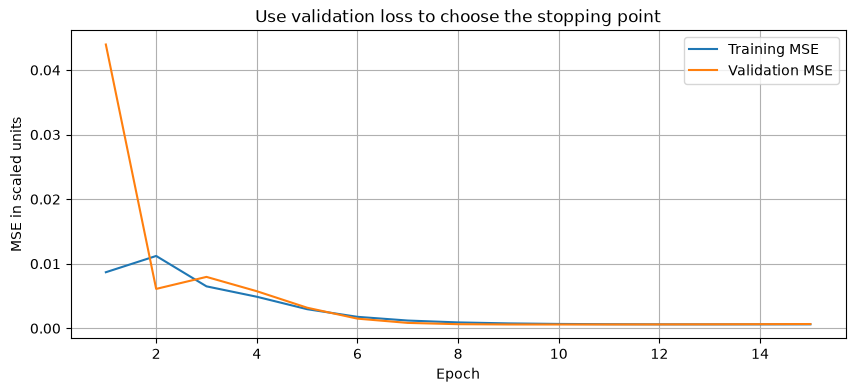

In [11]:
early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, min_delta=0.0,
    restore_best_weights=True
)
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
    shuffle=False, callbacks=[early_stop], verbose=0
)
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print(f"Ran {len(history.history['loss'])} epochs; lowest validation loss at epoch {best_epoch}.")

epochs = np.arange(1, len(history.history["loss"]) + 1)
plt.plot(epochs, history.history["loss"], label="Training MSE")
plt.plot(epochs, history.history["val_loss"], label="Validation MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE in scaled units")
plt.title("Use validation loss to choose the stopping point")
plt.legend()
plt.show()


## 6 · Compare on validation dates in original units

Inverse-transform predictions into a new array. Do not overwrite `y_train`, `y_val` or
`y_test`; they stay as scaled column vectors so that re-running training remains valid.
Record your configuration and validation metrics before changing one setting.


                       MAE    RMSE
Last observed value  7.157   9.852
RNN                  8.849  12.051
{'LOOKBACK': 10, 'UNITS': 16, 'seed': 42, 'epochs_run': 15, 'best_epoch': 10}


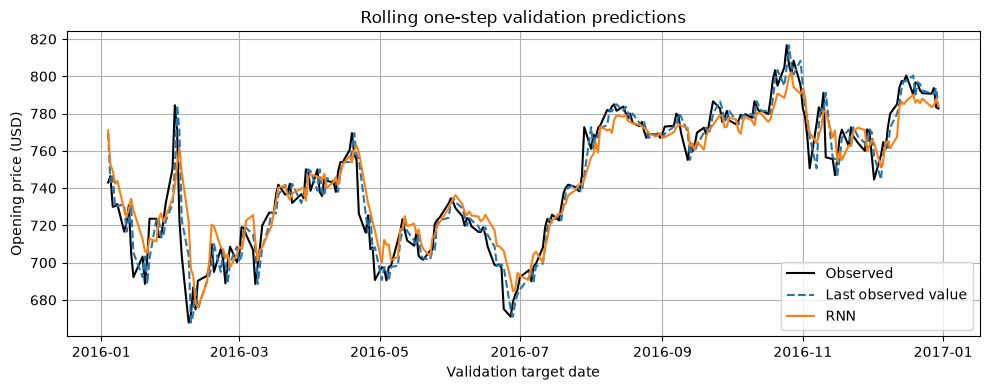

In [12]:
val_pred_scaled = model.predict(X_val, verbose=0)
val_pred = scaler.inverse_transform(val_pred_scaled)[:, 0]
validation_scores = pd.concat([
    baseline_validation,
    pd.DataFrame([error_scores(val_actual, val_pred)], index=["RNN"])
])
print(validation_scores.round(3).to_string())
print({"LOOKBACK": LOOKBACK, "UNITS": UNITS, "seed": SEED,
       "epochs_run": len(history.history["loss"]), "best_epoch": best_epoch})

plt.plot(dates[val_pos], val_actual, label="Observed", color="black")
plt.plot(dates[val_pos], val_last, label="Last observed value", linestyle="--")
plt.plot(dates[val_pos], val_pred, label="RNN")
plt.xlabel("Validation target date")
plt.ylabel("Opening price (USD)")
plt.title("Rolling one-step validation predictions")
plt.legend()
plt.tight_layout()
plt.show()


## Learner response · complete before the final test

**Shape and data explanation:** With the supplied `LOOKBACK = 20`, `X_train` is `(986, 20, 1)`: 986 samples (training target positions 20…1005), 20 timesteps (the previous 20 trading-day opening prices) and 1 feature (the opening price). `y_train` is `(986, 1)`. `UNITS = 16` is the size of the SimpleRNN hidden state, i.e. how many numbers the layer carries from one timestep to the next; it is a model setting and has nothing to do with the input shape. The first validation example uses the inputs from 2015-12-03 to 2015-12-31 (the last 20 training days) and its target is 2016-01-04. The first test input can use December 2016 history because, under the rolling one-step contract, all observations before the target date are already known when we predict it. Those December values are validation observations, not test targets, and the model and scaler are not refit on them.

**Hypothesis written before running alternatives:** I compare 20 with **10** trading days. I expect a 10-day window to be at least as good, because the next opening price depends mostly on the most recent prices. Older prices add little extra signal but give a SimpleRNN a longer chain of steps to pass gradients through. A shorter window also leaves 10 extra training samples.

| Lookback | Units | Train samples | Epochs run | Validation MAE | Validation RMSE |
|---|---|---|---|---|---|
| 20 | 16 | 986 | 23 (best epoch 18) | 12.520 | 16.808 |
| 10 | 16 | 996 | 30 (best epoch 25) | 10.327 | 14.369 |

**Baseline validation scores:** Persistence (last observed opening price) on the same 252 validation target dates (2016-01-04 to 2016-12-30): MAE **7.157 USD**, RMSE **9.852 USD**. Neither RNN beats it.

**Chosen configuration and evidence:** `LOOKBACK = 10`, `UNITS = 16`, seed 42. It has the lower validation MAE (10.327 vs 12.520 USD) and also the lower RMSE, so the hypothesis was supported on validation. It is still about 3.2 USD worse than persistence, so on this evidence the honest recommendation is the persistence baseline. The 10-day model also used all 30 epochs, so it may be slightly under-trained under the fixed budget. I did not change that budget, because it is one of the controls.

**What remained constant?** The data files, the chronological split (train_end = 1006, val_end = 1258), the train-only scaler, the validation/test target dates (252 / 20 targets), seed 42, `UNITS = 16`, batch size 32, Adam with lr 0.001, `MAX_EPOCHS = 30`, and EarlyStopping (patience 5, restore best weights). Only `LOOKBACK` changed. The training sample count went from 986 to 996 because the first eligible target position is `t = LOOKBACK`, so a shorter window lets the first 10 extra training days become targets. Validation and test targets do not change, because their windows may reach back into earlier splits.

## 7 · Freeze the configuration, then evaluate test once

Before this section, record the chosen settings and why validation supports them.
Use the selected model already trained above; this lab does not refit on validation data.
Do not use the final test score to choose another configuration.

The model predicts every held-out target using the actual history available immediately
before it. There is no model/scaler refitting during these trading days. All methods use exactly
the same target dates. The starter skips this section until you set `RUN_FINAL_TEST = True` after completing the core tasks.


                        MAE    RMSE
Last observed value   5.944   8.416
RNN                  12.747  14.717
Final configuration: {'LOOKBACK': 10, 'UNITS': 16, 'seed': 42, 'best_epoch': 10}
Test targets scored: 20


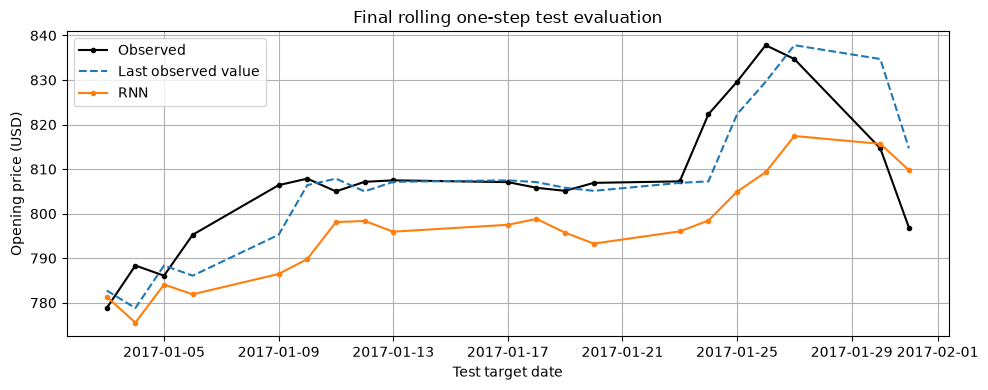

In [13]:
RUN_FINAL_TEST = True

if RUN_FINAL_TEST:
    test_actual = values[test_pos, 0].copy()
    test_last = values[test_pos - 1, 0].copy()
    test_pred = scaler.inverse_transform(model.predict(X_test, verbose=0))[:, 0]
    test_scores = pd.DataFrame({
        "Last observed value": error_scores(test_actual, test_last),
        "RNN": error_scores(test_actual, test_pred),
    }).T
    print(test_scores.round(3).to_string())
    print("Final configuration:", {"LOOKBACK": LOOKBACK, "UNITS": UNITS,
                                   "seed": SEED, "best_epoch": best_epoch})
    print("Test targets scored:", len(test_actual))

    plt.plot(dates[test_pos], test_actual, label="Observed", color="black", marker=".")
    plt.plot(dates[test_pos], test_last, label="Last observed value", linestyle="--")
    plt.plot(dates[test_pos], test_pred, label="RNN", marker=".")
    plt.xlabel("Test target date")
    plt.ylabel("Opening price (USD)")
    plt.title("Final rolling one-step test evaluation")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Test remains held out. Complete validation experiments and freeze settings first.")


## Final learner report and discussion

**Final test scores and limitation:** One final test run with the frozen configuration (`LOOKBACK = 10`, `UNITS = 16`, seed 42, best epoch 25), on 20 test trading days (2017-01-03 to 2017-01-31), in USD:

| Method | Test MAE | Test RMSE |
|---|---|---|
| Last observed value (persistence) | **5.944** | **8.416** |
| RNN | 16.443 | 18.853 |

Persistence is clearly better on test, as it was on validation, and the RNN's gap grew (about 10.5 USD worse in MAE vs about 3.2 on validation). I did not change any setting after seeing these scores. One reason the result may not generalise: January 2017 opening prices are above the training maximum (776.6 USD), so their scaled values are above 1. The model has to extrapolate outside the range it was trained on, and a small RNN tends to lag or flatten its predictions there. The test period is also only 20 days with a single seed, which is far too little evidence for future performance, and stock prices are close to a random walk, which is why persistence is so hard to beat.

**Discussion:** If the actual next observation were unavailable (forecasting several days ahead from a fixed origin), the model would have to feed its own predictions back in as inputs, or be trained as a direct multi-step model. Errors would then accumulate with the horizon, and the persistence baseline would have to repeat the same last known price for every horizon. The one-step scores above say nothing about that task. Observing earlier test values is allowed here because in a real daily forecast those prices really are known before the next prediction is made: they are inputs available at prediction time. Fitting on test targets is different. Updating weights, refitting the scaler or choosing settings using test labels lets the model or the selection learn from the very answers it is scored on, so the test score stops being an honest estimate of unseen performance.

Discuss: What changes if the actual next observation is unavailable? Why is observing earlier
test values allowed in this rolling evaluation, while fitting on test targets is not?
A short held-out period and one random seed do not establish reliable future performance.

## Optional extensions · after the core work

- Compare 8 and 32 recurrent units after fixing the window. Keep the target dates unchanged.
- Add a rolling-mean baseline using only observations before each target.
- Replace SimpleRNN with LSTM on **this same stock task**, keeping split, inputs, budget and
  metrics fixed. Do not compare its score with the airline lab to claim one architecture wins.
- Design a genuine multi-step experiment from a fixed forecast origin. If later observations
  are unknown, feed back predictions recursively or train a direct multi-output model. Evaluate
  each horizon using matching-origin baselines. The one-step score above does not measure this task.

## Sources and attribution

- Original supplied notebook attributed its tutorial to
  [moonglow22, RNN and LSTM tutorial for beginners](https://www.kaggle.com/code/moonglow22/rnn-and-lstm-tutorial-for-beginners/notebook)
  and stated Apache 2.0 for that notebook. This attribution is retained; it is not a data license.
- Data: [Kaggle dataset, version 1](https://www.kaggle.com/datasets/rahulsah06/gooogle-stock-price).
  The source metadata reports **Unknown** license. Included CSVs are source copies for review;
  see `data/DATA_SOURCES.md` in the complete pack before wider distribution.
- [Keras backend setup](https://keras.io/getting_started/),
  [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html),
  [avoiding preprocessing leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage),
  [KaggleHub versioned downloads](https://github.com/Kaggle/kagglehub#download-dataset).
